# Chan et al. 2021 — Lung (SCLC) · 03 Signatures

Raw signature UMAPs (Gast/pSom/Crest) in house `(3.5,1.5)` style with external colorbars, then
**Gate 2** on the module geography. Deliverable UMAPs show **raw** per-cell scores (smoothing aids
the geography read in 02 but the deliverable is the honest per-cell readout).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth,'data')
pth_in  = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude','Lung',name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude','Lung',name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)

### Load `manifold.h5ad`

In [2]:
adata = sc.read_h5ad(os.path.join(pth_in,'manifold.h5ad')); print(adata.n_obs,'cells')
adata.obsm['X_umap'] = adata.obsm['X_umap_lin'].copy()   # house orientation, origin left

50881 cells


### Gate 2 — module geography (non-branching)

Gast and pSom **co-vary** (positive smoothed r — overlap, not competitive cross-repression) and
Crest is an **inverse/terminal gradient** rising where pSom falls (strongly negative pSom↔Crest r).
This is the non-branching case (§1): a single embryonic axis, not a hub diverging into two
gradient-opposed arms. It **passes Gate 2 (GO)**; with no bifurcation, **Gate 3 is NA**. There are no
arms, so Crest cannot enrich a Gast arm — no inversion flag.

In [3]:
S = adata.obs[['Gast_sm','pSom_sm','Crest_sm']].corr()
print('smoothed spatial correlations:'); print(S.round(3))
print('\nGast<->pSom = %+.3f (co-vary, positive => non-branching, not cross-repression)' % S.loc['Gast_sm','pSom_sm'])
print('pSom<->Crest = %+.3f (inverse terminal gradient)' % S.loc['pSom_sm','Crest_sm'])
print('\nGate 2 = GO (non-branching / Linear);  Gate 3 = NA;  Crest-arm flag = none')

smoothed spatial correlations:
          Gast_sm  pSom_sm  Crest_sm
Gast_sm     1.000    0.477    -0.520
pSom_sm     0.477    1.000    -0.802
Crest_sm   -0.520   -0.802     1.000

Gast<->pSom = +0.477 (co-vary, positive => non-branching, not cross-repression)
pSom<->Crest = -0.802 (inverse terminal gradient)

Gate 2 = GO (non-branching / Linear);  Gate 3 = NA;  Crest-arm flag = none


### Deliverables — raw signature UMAPs + external colorbars (house style)

`figsize=(3.5,1.5)`, `cmap='plasma'`, shared house orientation, one external colorbar per module.

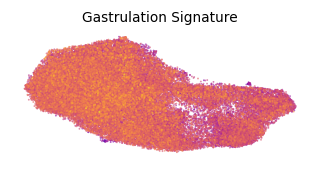

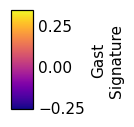

In [4]:
def sig_panel(col, title, lab):
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(adata, color=col, cmap='plasma', alpha=.6, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax)
    ax.set_title(title, size=9)
    fig.savefig(os.path.join(pth_fig, f'{lab}_signature.pdf'), bbox_inches='tight')
    figc = plt.figure(figsize=(.66,1)); cax = figc.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{lab}\nSignature'); cb.solids.set_alpha(1)
    figc.savefig(os.path.join(pth_cb, f'{lab}_colorbar.pdf'), bbox_inches='tight')
    return fig
sig_panel('Gast','Gastrulation Signature','Gast'); plt.show()

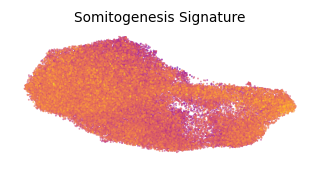

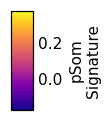

In [5]:
sig_panel('pSom','Somitogenesis Signature','pSom'); plt.show()

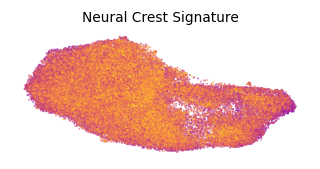

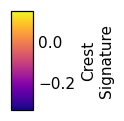

In [6]:
sig_panel('Crest','Neural Crest Signature','Crest'); plt.show()

### Save `signatures.h5ad`

In [7]:
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in,'signatures.h5ad')); print('saved signatures.h5ad')

saved signatures.h5ad
